In [84]:
from utils import load_splits, tokenize_dataset, compute_metrics, classification_metrics
import torch
import pandas as pd

In [85]:
#global random seed
SEED = 42
torch.manual_seed(SEED)

In [86]:
X_train, X_val, X_test, y_train, y_val, y_test = load_splits()

In [87]:
df_test = pd.merge(X_test, y_test, left_index=True, right_index=True)
df_test

,title,labels
0,Hillary Clinton’s Backers Thought She Couldn’t...,0
1,It Took A Democratic Governor To Finally Call ...,1
2,Trump’s New Defense Strategy On ‘Access Hollyw...,1
3,Elysee plays down opulence of Macron birthday ...,0
4,"Trump says 'his decision' to fire FBI chief, c...",0
...,...,...
9191,Trump disbands business councils after CEOs qu...,0
9192,WATCH: NBC Reporter Calls Trump Out For Lying ...,1
9193,MASSACHUSETTS VOTES TO IGNORE FED LAW and Let ...,1
9194,F.B.I. Investigating if Fatal Plane Crash in E...,0


In [88]:
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

True
NVIDIA GeForce RTX 3050 6GB Laptop GPU


device(type='cuda')

In [89]:
import json
from pathlib import Path

logs = {
    file.stem: json.loads(file.read_text())
    for file in Path("logs").glob("*.json")
}


In [90]:
val_metrics = []
for run_name, metrics in logs.items():
    if run_name == "logistic_regression":
        val_metrics.append({**metrics, "model": "baseline", "run_name": run_name,
                            "learning_rate": float("nan"), "epoch": float("nan")})
    else:
        model_name, learning_rate = run_name.rsplit("_", 1)
        for epoch in metrics:
            val_metrics.append({**epoch, "model": model_name, "run_name": run_name,
                                "learning_rate": float(learning_rate)})


In [91]:
val = pd.DataFrame(val_metrics)

if "loss" not in val:
    val["loss"] = float("nan")

val = val.sort_values("model").reset_index(drop=True)

val = val.drop(columns=["grad_norm", "eval_runtime", "eval_samples_per_second", "eval_steps_per_second"], errors="ignore")

val

,eval_accuracy,eval_precision_macro,eval_recall_macro,eval_f1_macro,eval_log_loss,model,run_name,learning_rate,epoch,loss,step,eval_loss
0,0.835581,0.834154,0.831706,0.832761,0.366726,baseline,logistic_regression,NaN,NaN,NaN,NaN,NaN
1,0.906590,0.907383,0.903030,0.904846,0.221140,bert-base-uncased,bert-base-uncased_3e-05,0.00003,1.0,0.285004,1342.0,0.221139
2,0.908873,0.906827,0.910648,0.908125,0.248837,bert-base-uncased,bert-base-uncased_3e-05,0.00003,2.0,0.147915,2684.0,0.248837
3,0.909308,0.909010,0.906872,0.907842,0.426077,bert-base-uncased,bert-base-uncased_3e-05,0.00003,3.0,0.073323,4026.0,0.426088
4,0.910505,0.909733,0.908660,0.909169,0.501860,bert-base-uncased,bert-base-uncased_3e-05,0.00003,4.0,0.031934,5368.0,0.501893
5,0.912353,0.912161,0.909907,0.910926,0.586401,bert-base-uncased,bert-base-uncased_3e-05,0.00003,5.0,0.014437,6710.0,0.586464
6,0.903001,0.904944,0.898435,0.900961,0.225149,bert-base-uncased,bert-base-uncased_4e-05,0.00004,1.0,0.283855,1342.0,0.225148
7,0.907242,0.905181,0.908905,0.906467,0.265238,bert-base-uncased,bert-base-uncased_4e-05,0.00004,2.0,0.143830,2684.0,0.265235
8,0.911375,0.910785,0.909337,0.910013,0.400255,bert-base-uncased,bert-base-uncased_4e-05,0.00004,3.0,0.065835,4026.0,0.400262
9,0.912027,0.910741,0.910969,0.910854,0.490236,bert-base-uncased,bert-base-uncased_4e-05,0.00004,4.0,0.027222,5368.0,0.490261


In [92]:
val["display_name"] = val.apply(
    lambda row: "baseline" if row["model"] == "baseline" else
    f"{row['model'][0]}_lr_{row['learning_rate']:.0e}_e_{row['epoch']:.0f}",
    axis=1,
)


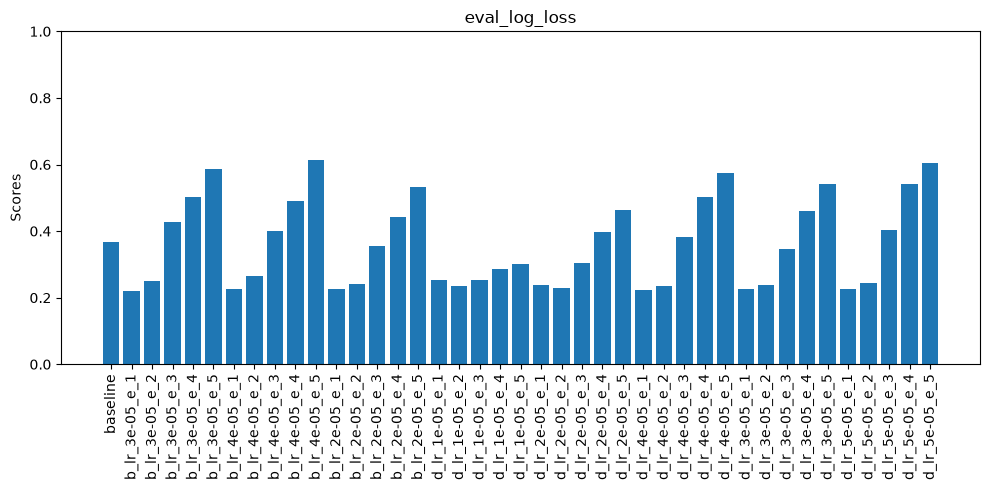

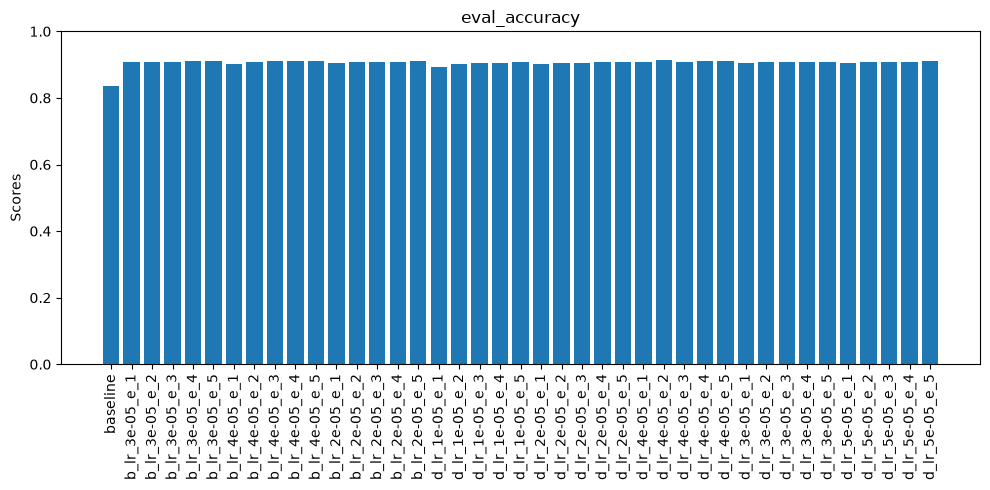

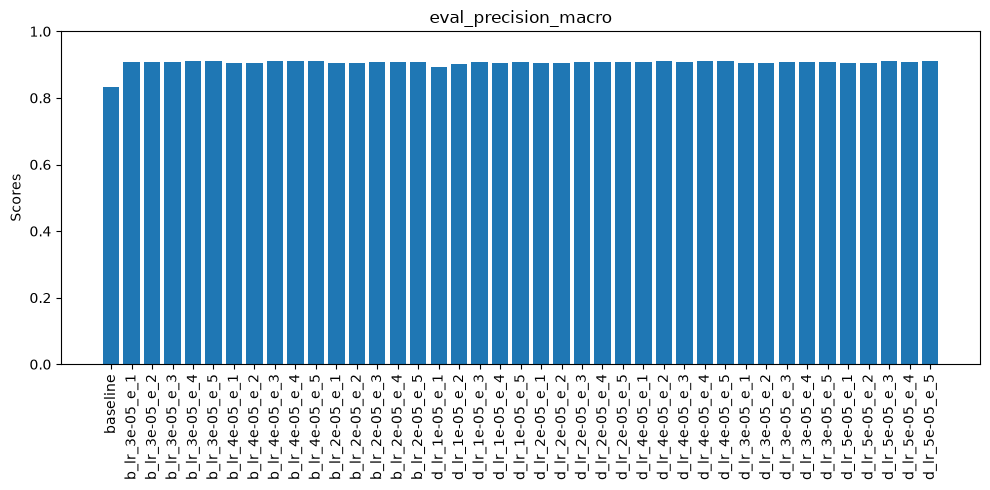

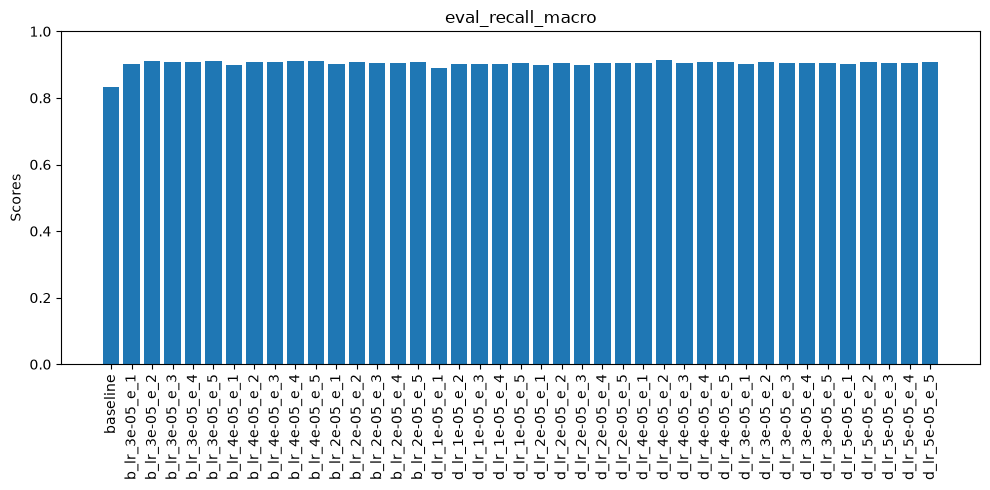

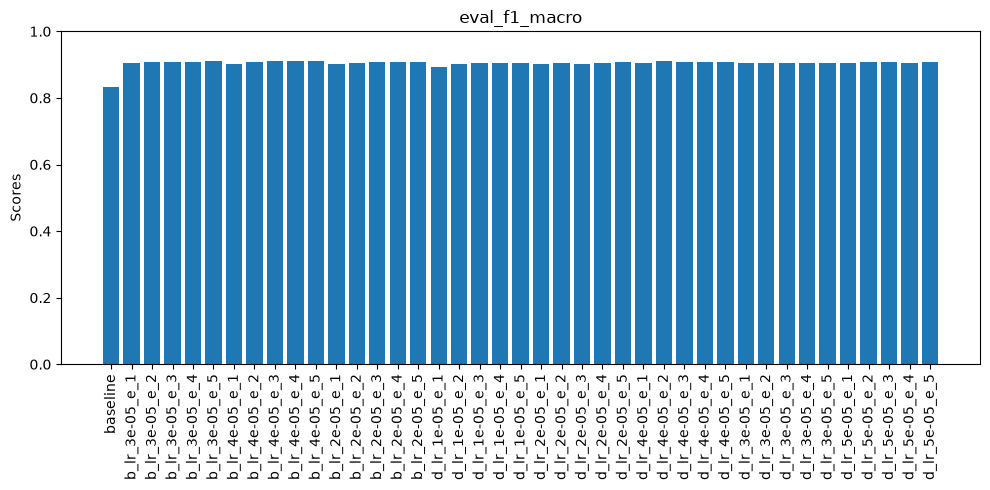

In [93]:
import matplotlib.pyplot as plt

metrics = ['eval_log_loss', 'eval_accuracy', 'eval_precision_macro', 'eval_recall_macro', 'eval_f1_macro']



for index, metric in enumerate(metrics):
    fig, axes = plt.subplots(figsize = (10,5))

    axes.bar(val["display_name"], val[metric])
    axes.set_title(metric)
    axes.set_ylim(0,1)
    axes.set_ylabel('Scores')
    axes.tick_params(axis="x", labelrotation=90)
    plt.tight_layout()
    plt.show()



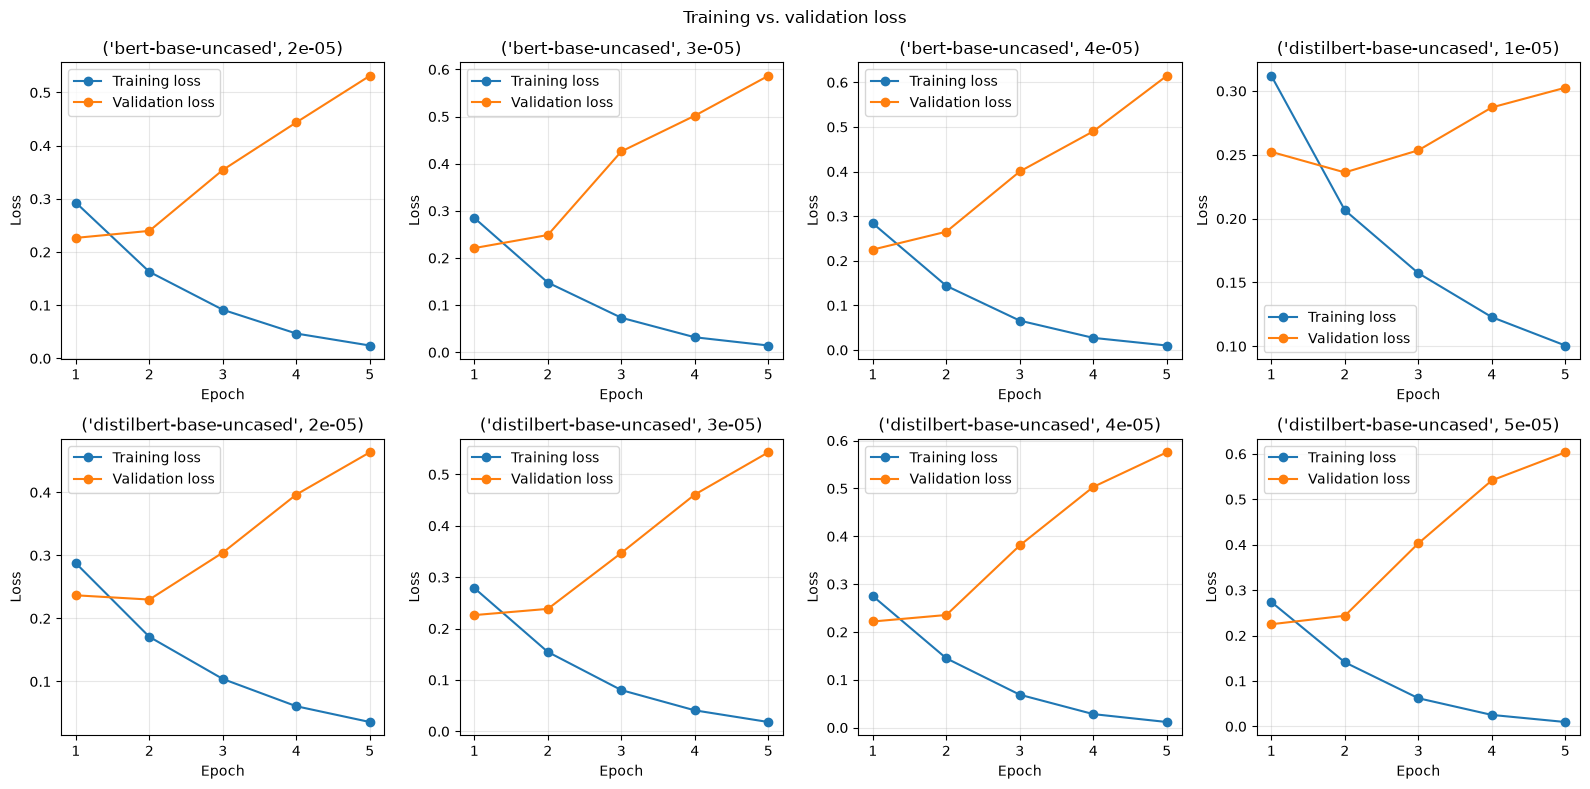

In [94]:
loss_val = val.dropna(subset=["loss", "eval_loss"]).copy()
loss_val = loss_val.sort_values(["model", "epoch"])

groups = list(loss_val.groupby(["model", "learning_rate"], sort=True))
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for ax, (model_name, group) in zip(axes, groups):
    ax.plot(group["epoch"], group["loss"], marker="o", label="Training loss")
    ax.plot(group["epoch"], group["eval_loss"], marker="o", label="Validation loss")
    ax.set_title(model_name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)
    ax.legend()

for ax in axes[len(groups):]:
    ax.set_visible(False)

fig.suptitle("Training vs. validation loss")
plt.tight_layout()
plt.show()


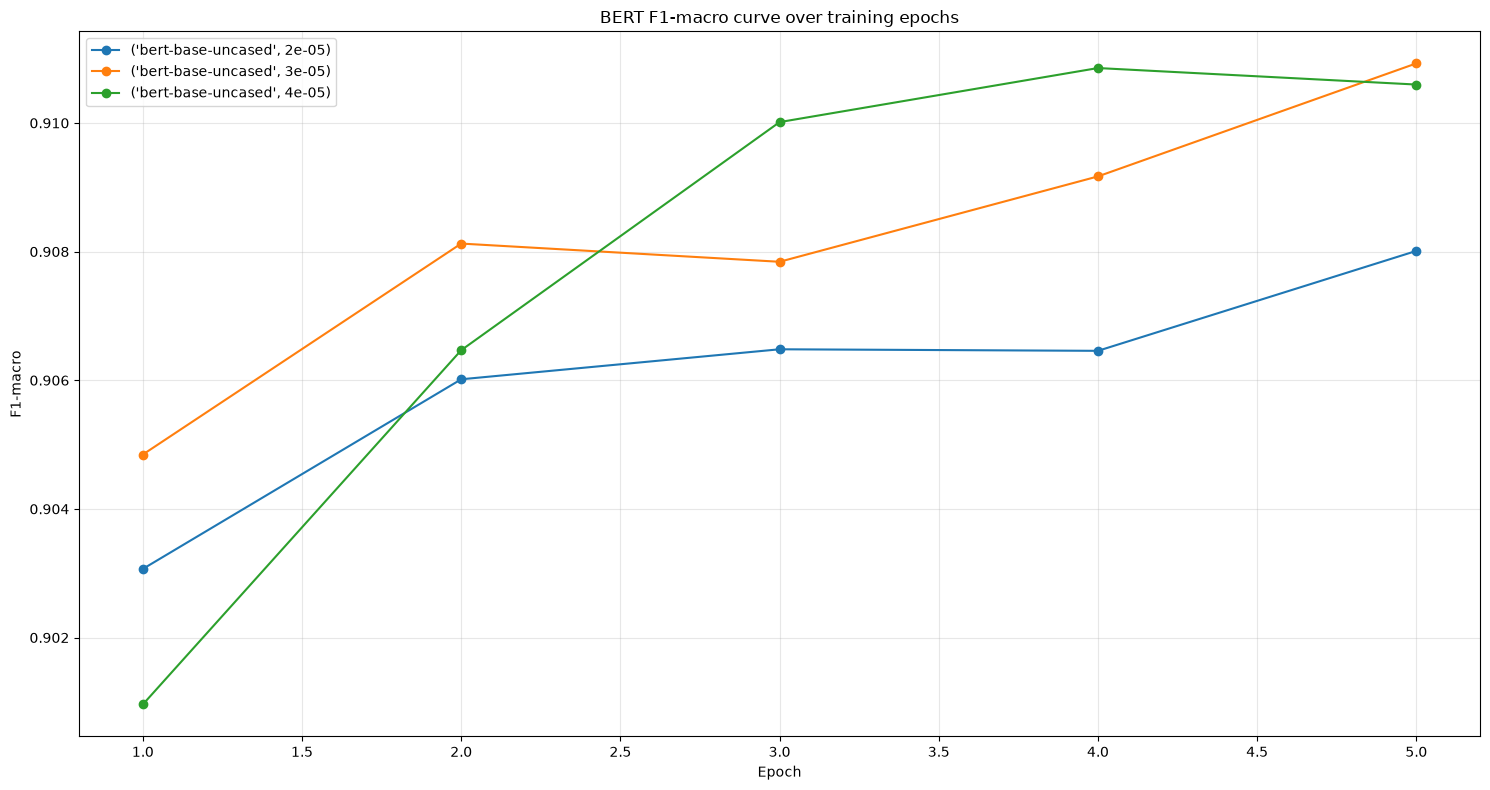

In [95]:
f1_macro_val = val[val["model"]=="bert-base-uncased"].dropna(subset=["loss", "eval_loss"]).copy()
f1_macro_val = f1_macro_val.sort_values(["model", "epoch"])

groups = list(f1_macro_val.groupby(["model", "learning_rate"], sort=True))
fig, ax = plt.subplots(figsize=(15, 8))


for (model_name, group) in groups:
    ax.plot(group["epoch"], group["eval_f1_macro"], marker="o", label=f"{model_name}")
ax.set_title('BERT F1-macro curve over training epochs')
ax.set_xlabel("Epoch")
ax.set_ylabel("F1-macro")
ax.grid(alpha=0.3)
ax.legend()

for ax in axes[len(groups):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

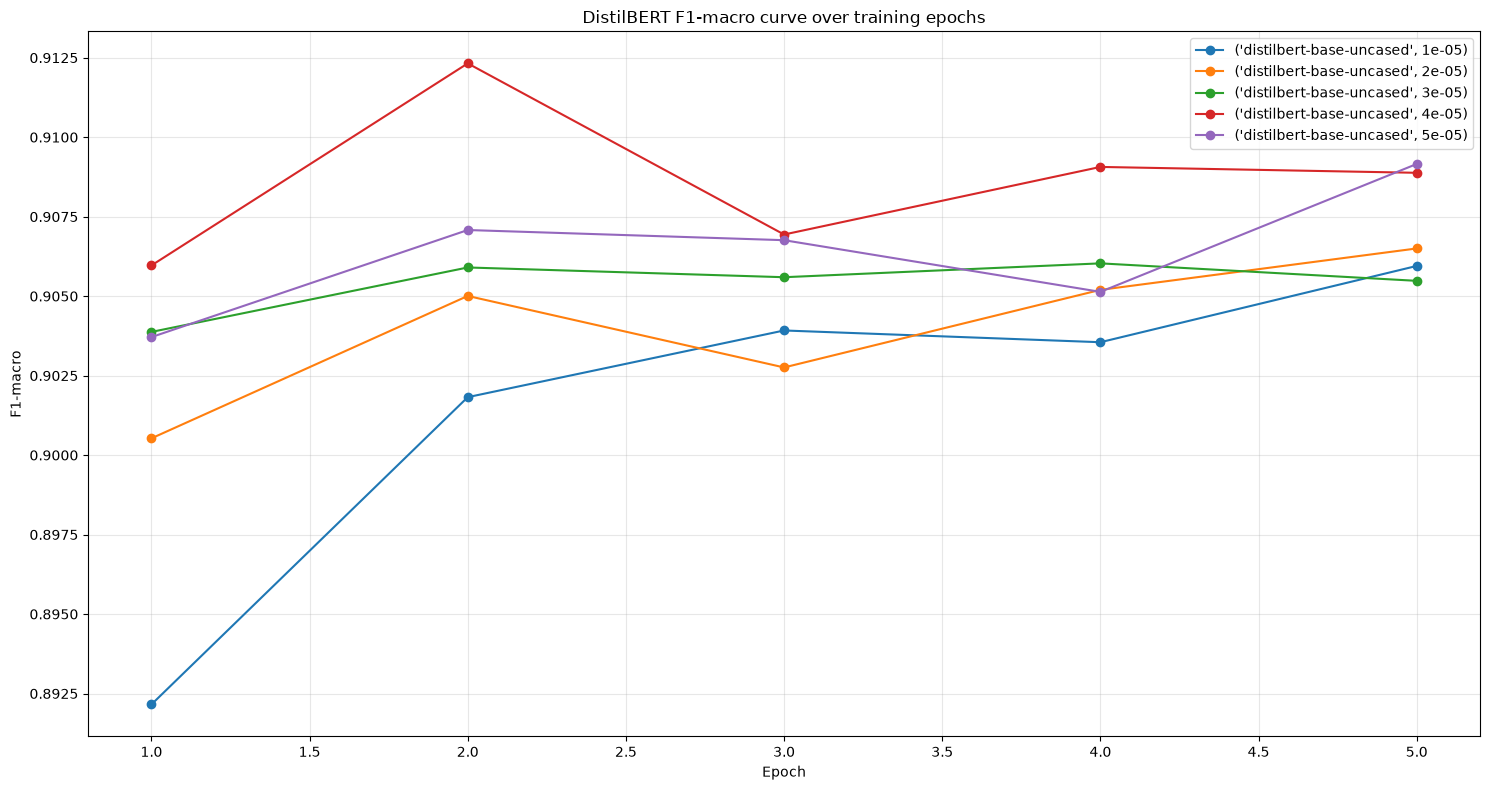

In [96]:
f1_macro_val = val[val["model"]=="distilbert-base-uncased"].dropna(subset=["loss", "eval_loss"]).copy()
f1_macro_val = f1_macro_val.sort_values(["model", "epoch"])

groups = list(f1_macro_val.groupby(["model", "learning_rate"], sort=True))
fig, ax = plt.subplots(figsize=(15, 8))


for (model_name, group) in groups:
    ax.plot(group["epoch"], group["eval_f1_macro"], marker="o", label=f"{model_name}")
ax.set_title('DistilBERT F1-macro curve over training epochs')
ax.set_xlabel("Epoch")
ax.set_ylabel("F1-macro")
ax.grid(alpha=0.3)
ax.legend()

for ax in axes[len(groups):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

In [97]:
distilbert = val[val["model"] == "distilbert-base-uncased"]
best_distil =distilbert[(distilbert["eval_f1_macro"]==distilbert["eval_f1_macro"].max())]
bert = val[val["model"] == "bert-base-uncased"]
best_bert = bert[(bert["eval_f1_macro"]==bert["eval_f1_macro"].max())]

selected = pd.concat([best_bert, best_distil])

selected

,eval_accuracy,eval_precision_macro,eval_recall_macro,eval_f1_macro,eval_log_loss,model,run_name,learning_rate,epoch,loss,step,eval_loss,display_name
5,0.912353,0.912161,0.909907,0.910926,0.586401,bert-base-uncased,bert-base-uncased_3e-05,0.00003,5.0,0.014437,6710.0,0.586464,b_lr_3e-05_e_5
27,0.913332,0.911622,0.913161,0.912322,0.235527,distilbert-base-uncased,distilbert-base-uncased_4e-05,0.00004,2.0,0.144917,2684.0,0.235525,d_lr_4e-05_e_2


In [98]:
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding,
)

selected_models = {}
for _, row in selected.drop_duplicates("model").iterrows():
    checkpoint = Path("models") / row["run_name"] / f"checkpoint-{int(row['step'])}"
    selected_models[row["model"]] = str(checkpoint)


predictions = {}
for model_name, checkpoint_path in selected_models.items():
    
    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint_path
    )
    ds_test = tokenize_dataset(X_test, y_test, checkpoint_path)

    tokenizer = AutoTokenizer.from_pretrained(checkpoint_path)

    trainer = Trainer(
        model=model,
        args=TrainingArguments(
            output_dir=f"evaluation/{model_name}",
            per_device_eval_batch_size=64,
            report_to="none",
        ),
        processing_class=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer),
        compute_metrics=compute_metrics,
    )
    predictions[model_name] = trainer.predict(ds_test)

Map: 100%|██████████| 9196/9196 [00:00<00:00, 25563.55 examples/s]


Map: 100%|██████████| 9196/9196 [00:02<00:00, 3109.73 examples/s] 


In [99]:
results = []
for model_name, prediction in predictions.items():
    metrics = prediction.metrics
    metrics["model_name"] = model_name[:10] #shorten the name, with 10 characters, both bert and distilbert have meaningful names
    results.append(metrics)


In [100]:
import time
import joblib
import numpy as np


baseline_model = joblib.load("models/logistic_regression.pkl")

start = time.perf_counter()

y_pred = baseline_model.predict(X_test)

runtime = time.perf_counter() - start

y_prob = baseline_model.predict_proba(X_test)

baseline_metrics = {
    "model_name": "baseline",
    **{f"test_{key}": value for key, value in classification_metrics(y_test, y_pred, probabilities=y_prob).items()},
    "test_runtime": runtime,
    "test_samples_per_second": len(X_test) / runtime,
    "test_steps_per_second": 0, #this is zero so the graph can work
}
results.append(baseline_metrics)


test_metrics = pd.DataFrame(results)

In [101]:
test_metrics

,test_loss,test_model_preparation_time,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_log_loss,test_runtime,test_samples_per_second,test_steps_per_second,model_name
0,0.523456,0.0038,0.919313,0.918966,0.917274,0.918058,0.523456,20.024300,459.241000,7.191,bert-base-
1,0.224518,0.0012,0.916485,0.914757,0.916500,0.915538,0.224518,10.265400,895.823000,14.028,distilbert
2,NaN,NaN,0.840365,0.838266,0.838021,0.838141,0.361880,0.186291,49363.751912,0.000,baseline


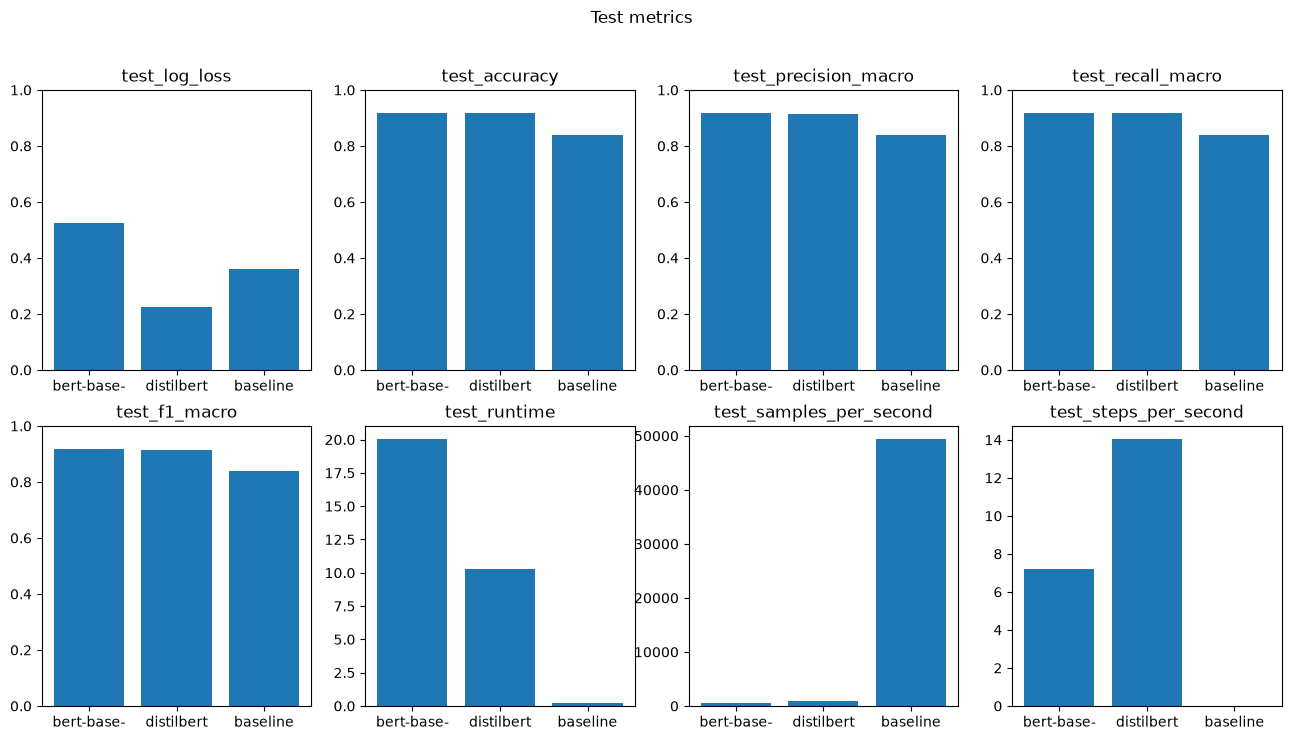

In [102]:
fig, axes = plt.subplots(2,4, figsize = (16,8), sharey = False)

metrics = ['test_log_loss', 'test_accuracy', 'test_precision_macro', 'test_recall_macro',
           'test_f1_macro', 'test_runtime', 'test_samples_per_second', 'test_steps_per_second']


for index, metric in enumerate(metrics):
    i = index // 4
    j = index % 4

    axes[i, j].bar(test_metrics["model_name"], test_metrics[metric])
    axes[i, j].set_title(metric)
    if index < 5:
        axes[i, j].set_ylim(0,1)
    #axes[i, j].tick_params(axis="x", labelrotation=90)

fig.suptitle("Test metrics")
plt.show()



The transformer models are significantly better at inference than the baseline. The bert model is marginally better at inference, but in such a small amount that it may as we be a numerical precision error. The distilbert model's Inference speed, and logloss, however, are significantly better, therefore this will be the chosen model for gradio deployment.

test logloss is still quite high, the model shows signs of overconfidence. Therefore, we will use temperature scaling to minimize validation logloss, then well evaluate on the test set.

In [103]:
ds_val = tokenize_dataset(X_val, y_val, "distilbert-base-uncased")

Map: 100%|██████████| 9196/9196 [00:00<00:00, 31565.10 examples/s]


In [104]:
import torch
import torch.nn.functional as F
from scipy.optimize import minimize_scalar

checkpoint_path = selected_models["distilbert-base-uncased"]
model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint_path
)
ds_val = tokenize_dataset(X_val, y_val, "distilbert-base-uncased")

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
trainer = Trainer(
    model=model,
    args=TrainingArguments(
        per_device_eval_batch_size=32,
        report_to="none",
    ),
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)
# Predictions from the selected checkpoint
output = trainer.predict(ds_val)

logits = torch.tensor(output.predictions, dtype=torch.float64)
labels = torch.tensor(output.label_ids, dtype=torch.long)

#search using a log-transform of the temperature for a more convenient search space

def calibration_loss(log_temperature):
    temperature = np.exp(log_temperature)

    loss = F.cross_entropy(
        logits / temperature,
        labels,
    )

    return loss.item()

result = minimize_scalar(
    calibration_loss,
    bounds=(-5, 5),
    method="bounded",
)

temperature = np.exp((result.x))

print(f"Optimal temperature: {temperature:.10f}")
print(f"Original validation loss: {calibration_loss(0):.4f}")
print(f"Calibrated validation loss: {calibration_loss(result.x):.4f}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Map: 100%|██████████| 9196/9196 [00:00<00:00, 27953.15 examples/s]


Optimal temperature: 1.4031190548
Original validation loss: 0.2355
Calibrated validation loss: 0.2193


The optimal temperature is 2.02, we will round to 2 for convenience. Now we wil compute the test logloss with the chosen temperature

In [105]:
from scipy.special import softmax
from sklearn.metrics import brier_score_loss

TEMP =temperature

test_output = trainer.predict(ds_test)

logits = torch.tensor(test_output.predictions, dtype=torch.float64)
y_true= torch.tensor(test_output.label_ids, dtype=torch.long)

original = softmax(logits, axis=1)
calibrated = softmax(logits / TEMP, axis=1)

for name, probs in [
    ("Original", original),
    ("Calibrated", calibrated),
]:
    print(name)
    metrics = classification_metrics(
        y_true, np.argmax(probs, axis=1), probabilities=probs
    )
    print("Log loss:", metrics["log_loss"])
    print("Brier score:", brier_score_loss(y_true, probs[:, 1]))
    print("Mean confidence:", probs.max(axis=1).mean())

Original
Log loss: 0.2245183075912298
Brier score: 0.06377613867192733
Mean confidence: 0.9459787995650547
Calibrated
Log loss: 0.21145577136929625
Brier score: 0.06211861798265409
Mean confidence: 0.9168725682592281


Mean confidence is still kinda high, but marginally better. 